## Day_26 - Decision Trees

## Part A - the basics: grow it, read it, judge it

## TASK 01 - Grow an unpruned tree and prove it overfits

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier

# Load dataset
df = pd.read_csv("loan_approval.csv")

# Separate features and target
X = df.drop(columns=["approved"])
y = df["approved"]

# Convert employed column into numeric values if it contains Yes/No
if X["employed"].dtype == "object":
    X["employed"] = X["employed"].map({
        "Yes": 1,
        "No": 0
    })

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# TASK 01: Train an unpruned Decision Tree
tree = DecisionTreeClassifier(random_state=42)

tree.fit(X_train, y_train)

# Print tree structure
print("Tree Depth:", tree.get_depth())
print("Number of Leaves:", tree.get_n_leaves())

# Calculate accuracy
train_accuracy = tree.score(X_train, y_train)
test_accuracy = tree.score(X_test, y_test)

print("\nTraining Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

# Compare both accuracies
print("\nAccuracy Comparison:")
print("Train:", round(train_accuracy * 100, 2), "%")
print("Test :", round(test_accuracy * 100, 2), "%")

# Overfitting explanation
print("\nConclusion:")
print("The unpruned tree can memorize training data,")
print("but performs worse on unseen testing data,")
print("which indicates overfitting.")


1\. What does it mean if every leaf contains exactly one training point?

It means the Decision Tree has memorized individual training samples, which indicates a high risk of overfitting.

2\. Why does training accuracy of 1.0 tell you almost nothing useful?

Because 100% training accuracy only shows that the model predicts training data perfectly. It does not guarantee good performance on unseen data.

3\. Roughly how many parameters does a tree with N leaves encode?

A binary tree with N leaves has approximately 2N − 1 total nodes (N leaves and N − 1 internal nodes). Each internal node stores a split rule, and each leaf stores a prediction.

## TASK 02 - Sweep max_depth and find the sweet spot

Best Depth: 3
Best Training Accuracy: 0.805
Best Testing Accuracy: 0.8067


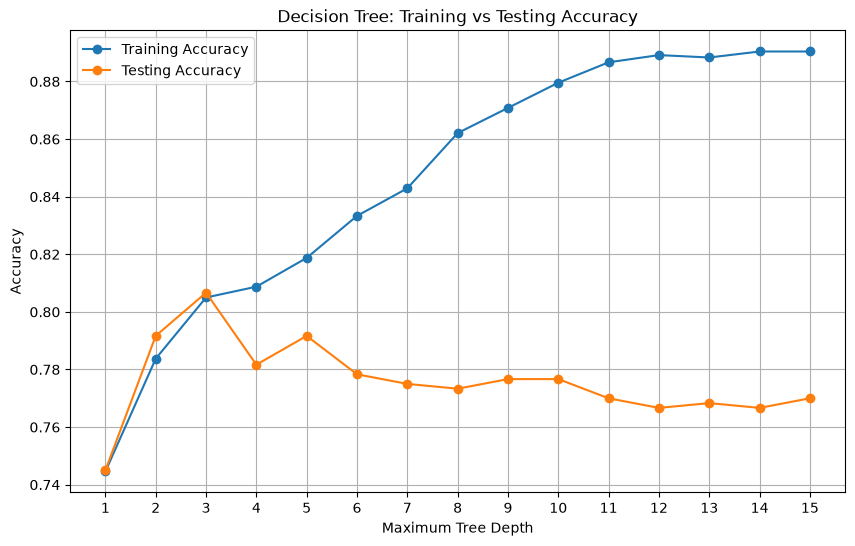

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier

# Load dataset
df = pd.read_csv("loan_approval.csv")

# Separate features and target
X = df.drop(columns=["approved"])
y = df["approved"]

# Convert employed column into numeric values if needed
if X["employed"].dtype == "object":
    X["employed"] = X["employed"].map({
        "Yes": 1,
        "No": 0
    })

# Train-test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# TASK 02: Test different tree depths
depths = range(1, 16)

train_accuracies = []
test_accuracies = []

for depth in depths:

    model = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_leaf=5,
        random_state=42
    )

    # Train model
    model.fit(X_train, y_train)

    # Calculate accuracy
    train_accuracies.append(model.score(X_train, y_train))
    test_accuracies.append(model.score(X_test, y_test))


# Find the best depth
best_depth = list(depths)[test_accuracies.index(max(test_accuracies))]

print("Best Depth:", best_depth)
print("Best Training Accuracy:", round(train_accuracies[best_depth - 1], 4))
print("Best Testing Accuracy:", round(test_accuracies[best_depth - 1], 4))


# Plot training and testing accuracy
plt.figure(figsize=(10, 6))

plt.plot(
    depths,
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depths,
    test_accuracies,
    marker="o",
    label="Testing Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: Training vs Testing Accuracy")
plt.xticks(list(depths))
plt.legend()
plt.grid(True)

plt.show()


1\. Why does training accuracy rise monotonically as depth grows?

As tree depth increases, the model gets more flexibility to learn patterns and details from training data. Therefore, training accuracy generally increases.

2\. Why does test accuracy fall after a certain depth instead of staying flat?

Because the tree starts learning noise and unnecessary details from training data, causing overfitting and reducing its performance on unseen test data.

3\. What happens if you change `min_samples_leaf` to 1 or 50?

- `min_samples_leaf=1`: Allows very small leaf nodes, making the tree more complex and increasing the risk of overfitting.
- `min_samples_leaf=50`: Forces larger leaf nodes, making the tree simpler and potentially causing underfitting.

## Part B - read the model back

## TASK 03 - Draw the tree and read it as rules

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split


# Load dataset
df = pd.read_csv("loan_approval.csv")

# Separate features and target
X = df.drop(columns=["approved"])
y = df["approved"]

# Convert employed column into numeric values if needed
if X["employed"].dtype == "object":
    x["employed"] = X["employed"].str.strip().str.lower().map({
        "yes": 1,
        "no": 0
    })

# Train-test split
X_train , X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create a pruned Decision Tree
tree = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=5,
    random_state=42
)

# Train the model
tree.fit(X_train, y_train)

# Print model performance
print("Training Accuracy:", tree.score(X_train, y_train))
print("Testing Accuracy:", tree.score(X_test, y_test))

print("Tree Depth:", tree.get_depth())
print("Number of Leaves:", tree.get_n_leaves())

# Visualize the Decision Tree
plt.figure(figsize=(22, 12))

plot_tree(
    tree,
    filled=True,
    rounded=True,
    feature_names=X.columns,
    class_names=["Not Approved", "Approved"],
    fontsize=9
)

plt.title("Pruned Decision Tree - Loan Approval")
plt.show()


# Extract the top 3 decision rules

from sklearn.tree import export_text

# Extract decision rules
rules = export_text(
    tree,
    feature_names=list(X.columns)
)

print(rules)



1\. Given the root split, which two features dominate loan approval, and why does that make sense for a bank?

Credit score and income are important factors in loan approval because banks use them to evaluate a borrower's creditworthiness and ability to repay a loan.

Note: Check your actual tree's root split and next-level split to identify the two features it selected.

2\. What does `filled=True` do to each node's colour, and how does the shading relate to the predicted class?

`filled=True` adds colours to tree nodes based on their predicted class. Darker shading indicates a purer node (more samples belong to the predicted class), while lighter shading indicates a more mixed node.

## TASK 04 - Rank the features with feature_importance_

Feature Importance (Highest to Lowest):
     Feature  Importance
  debt_ratio    0.498698
credit_score    0.291660
      income    0.070149
         age    0.062245
   num_loans    0.043182
    employed    0.034066


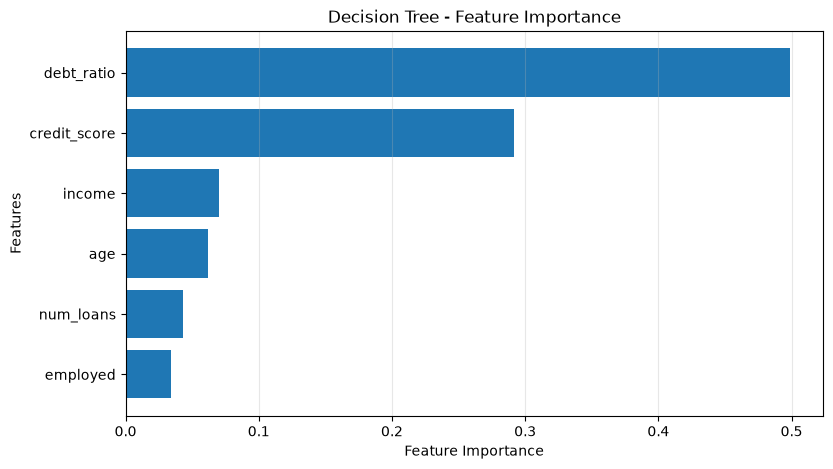


Top Two Important Features: ['debt_ratio', 'credit_score']
Root Split Feature: debt_ratio
Does the root feature appear in the top two? True


In [2]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

# Load dataset
df = pd.read_csv("loan_approval.csv")

# Separate features and target
X = df.drop(columns=["approved"])
y = df["approved"]

# Convert employed column into numeric values if needed
if X["employed"].dtype == "object":
    X["employed"] = X["employed"].str.strip().str.lower().map({
        "yes": 1,
        "no": 0
    })

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create pruned Decision Tree
tree = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=5,
    random_state=42
)

# Train model
tree.fit(X_train, y_train)

# Calculate feature importance
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": tree.feature_importances_
})

# Sort features by importance
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

# Print feature importance
print("Feature Importance (Highest to Lowest):")
print(importance.to_string(index=False))

# Plot sorted bar chart
plt.figure(figsize=(9, 5))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Decision Tree - Feature Importance")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.show()

# Display top two features
top_two = importance["Feature"].head(2).tolist()

print("\nTop Two Important Features:", top_two)

# Root split feature
root_feature = X.columns[tree.tree_.feature[0]]

print("Root Split Feature:", root_feature)

# Compare root feature with feature importance
print(
    "Does the root feature appear in the top two?",
    root_feature in top_two
)


1\. What do the feature importance values sum to, and how should you read a feature near zero (like age)?

Feature importance values sum to 1 (100%). A value near zero means the feature contributes very little to reducing impurity in the trained Decision Tree.

2\. Why might feature importance be misleading if two features are highly correlated?

Because two correlated features provide similar information. The tree may use one more than the other, making the unused feature appear less important even though both contain useful information.

## Part C - regularize and compare scientifically

## TASK 05 - Use cross-validation and a single pipeline to tune honestly

Best depth: 3
Best CV Accuracy: 0.797


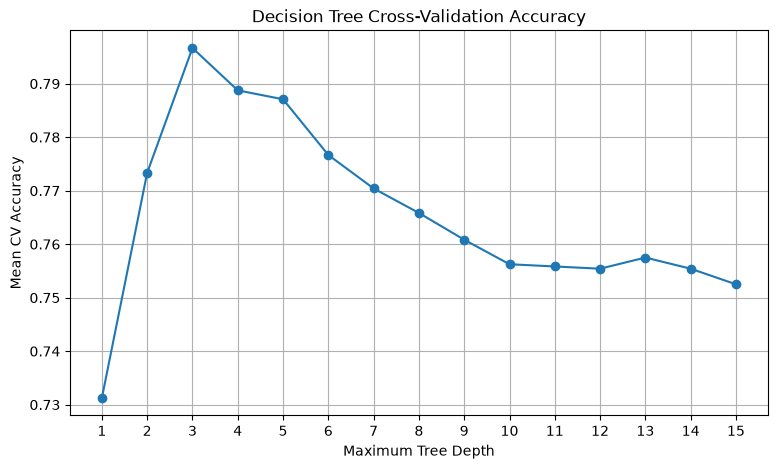

Held-out Test Accuracy: 0.807


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

# Load dataset
df = pd.read_csv("loan_approval.csv")

# Separate features and target
X = df.drop(columns=["approved"])
y = df["approved"]

# Convert categorical columns into numeric values
for col in X.select_dtypes(include=["object"]).columns:
    X[col] = X[col].astype(str).str.strip()

X = pd.get_dummies(X, drop_first=True, dtype=int)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create Decision Tree pipeline
pipe = Pipeline([
    ("tree", DecisionTreeClassifier(
        min_samples_leaf=5,
        random_state=42
    ))
])

# Perform 5-fold cross-validation for depths 1 to 15
scores = {}

for depth in range(1, 16):
    pipe.set_params(tree__max_depth=depth)

    cv_scores = cross_val_score(
        pipe,  X_train, y_train, cv=5, scoring="accuracy"
    )

    scores[depth] = cv_scores.mean()

# Find best depth
best_d = max(scores, key=scores.get)

print("Best depth:", best_d)
print("Best CV Accuracy:", round(scores[best_d], 3))

# Plot cross-validation scores
plt.figure(figsize=(9, 5))
plt.plot(scores.keys(), scores.values(), marker="o")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Mean CV Accuracy")
plt.title("Decision Tree Cross-Validation Accuracy")
plt.xticks(range(1, 16))
plt.grid(True)
plt.show()

# Train final model using the best depth
best_model = Pipeline([
    ("tree", DecisionTreeClassifier(
        max_depth=best_d,
        min_samples_leaf=5,
        random_state=42
    ))
])

best_model.fit(X_train, y_train)

# Evaluate held-out test set only once
y_pred = best_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)

print("Held-out Test Accuracy:", round(test_accuracy, 3))

## TASK 06 - Tree vs linear model: does the tree earn its place?

              Model  CV Accuracy  CV ROC-AUC
Logistic Regression        0.735       0.781
      Decision Tree        0.797       0.826


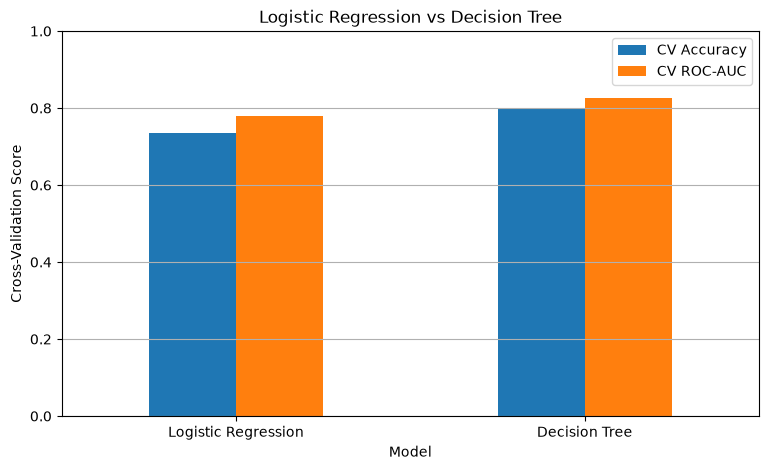

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Load dataset
df = pd.read_csv("loan_approval.csv")

# Separate features and target
X = df.drop(columns=["approved"])
y = df["approved"]

# Convert categorical columns into numeric values
for col in X.select_dtypes(include=["object"]).columns:
    X[col] = X[col].astype(str).str.strip()

X = pd.get_dummies(X, drop_first=True, dtype=int)

# Convert target labels if they are Yes/No
if y.dtype == "object":
    y_clean = y.astype(str).str.strip().str.lower()
    y = y_clean.map({"yes": 1, "no": 0}) if set(y_clean.unique()) <= {"yes", "no"} else y

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Logistic Regression with scaling
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

# Pruned Decision Tree using raw features
tree_model = DecisionTreeClassifier(
    max_depth=best_d if "best_d" in globals() else 4,
    min_samples_leaf=5,
    random_state=42
)

# Compare models using 5-fold cross-validation
scoring = ["accuracy", "roc_auc"]

logistic_scores = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=5,
    scoring=scoring
)

tree_scores = cross_validate(
    tree_model,
    X_train,
    y_train,
    cv=5,
    scoring=scoring
)

# Display results
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "CV Accuracy": [
        logistic_scores["test_accuracy"].mean(),
        tree_scores["test_accuracy"].mean()
    ],
    "CV ROC-AUC": [
        logistic_scores["test_roc_auc"].mean(),
        tree_scores["test_roc_auc"].mean()
    ]
})

print(results.round(3).to_string(index=False))

# Plot comparison
results.set_index("Model").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Logistic Regression vs Decision Tree")
plt.ylabel("Cross-Validation Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()